# 01 · Prepare ML240 frames and RAFT motion

Prepare the line drawings and motion estimates used to train InterFrames. Each example contains a start drawing, its true middle, and an end drawing.

**Setup:** Kaggle with a GPU and Internet enabled. The motion model runs in TensorFlow and keeps its pretrained weights.

**Saves:** `interframes_tf_stage1.zip`, containing 256 × 256 frames, train/validation/test lists, cached motion, and the Python modules used by later notebooks.

In [ ]:
import os, sys, json, time, shutil, platform, importlib.util, hashlib
from pathlib import Path
from collections import Counter

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML


assert Path("/kaggle").exists(), "These notebooks are intended for Kaggle."
assert tuple(map(int, tf.__version__.split(".")[:2])) >= (2, 16), (
    "Use a current Kaggle image with TensorFlow >=2.16 / Keras 3."
)

GPUS = tf.config.list_physical_devices("GPU")


assert GPUS, "Enable a GPU in Kaggle Session options before proceeding."


for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # Already configured in the same running session.


tf.config.experimental.enable_tensor_float_32_execution(False)
keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__, "Keras", keras.__version__, "GPUs", GPUS)


TensorFlow 2.21.0 Keras 3.13.2 GPUs [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
ROOT = Path("/kaggle/working/interframes_tf_stage1")
TEMP = Path("/kaggle/temp/interframes_tf")


RESUME_DATA_ROOT = None  # Optional saved PARTIAL output folder to continue flow preparation after a session ends.

MODULE_SOURCES = {
    "data.py": "\"\"\"Dataset, raster features, and evaluation utilities; no learning framework required.\"\"\"\nfrom pathlib import Path\nfrom collections import defaultdict, Counter\nimport hashlib, io, json, math, re, zipfile, time\nimport numpy as np\nfrom PIL import Image\nfrom scipy.ndimage import distance_transform_edt\n\ndef digest(path):\n    h = hashlib.sha256()\n    with open(path, 'rb') as f:\n        for chunk in iter(lambda: f.read(1024 * 1024), b''):\n            h.update(chunk)\n    return h.hexdigest()\n\ndef json_save(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    tmp = path.with_suffix(path.suffix + '.tmp')\n    tmp.write_text(json.dumps(value, indent=2))\n    tmp.replace(path)\n\ndef prepare_image(source, size=256):\n    \"\"\"Composite transparency on white, preserve aspect ratio, use a white canvas.\"\"\"\n    im = Image.open(source) if not isinstance(source, Image.Image) else source.copy()\n    im = im.convert('RGBA')\n    bg = Image.new('RGBA', im.size, 'white')\n    bg.alpha_composite(im)\n    im = bg.convert('L')\n    im.thumbnail((size, size), Image.Resampling.LANCZOS)\n    out = Image.new('L', (size, size), 255)\n    out.paste(im, ((size-im.width)//2, (size-im.height)//2))\n    return out\n\ndef read_ink(path):\n    with Image.open(path) as im:\n        return 1.0 - np.asarray(im.convert('L'), dtype=np.float32) / 255.0\n\ndef ink_image(ink):\n    return Image.fromarray(np.uint8(np.clip(1.0-ink, 0, 1)*255), mode='L')\n\ndef archive_sequences(zf):\n    \"\"\"Map documented archive folders to train/val/test, never randomize frames.\"\"\"\n    groups = defaultdict(list)\n    unknown = []\n    for member in zf.namelist():\n        p = Path(member)\n        if p.suffix.lower() != '.png' or 'frames' not in p.parts or '__MACOSX' in p.parts:\n            continue\n        parts = p.parts\n        k = parts.index('frames')\n        if k+2 != len(parts)-1:\n            unknown.append(member)\n            continue\n        prefix = parts[:k]\n        if 'ml144_norm_100_44_split' in prefix and prefix[-1] == 'train':\n            split = 'train'\n        elif 'ml144_norm_100_44_split' in prefix and prefix[-1] == 'test':\n            split = 'val'\n        elif 'ml100_norm' in prefix and prefix[-1] == 'all':\n            split = 'test'\n        else:\n            unknown.append(member)\n            continue\n        m = re.search(r'(\\d+)$', p.stem)\n        if not m:\n            raise ValueError(f'No frame number: {member}')\n        groups[(split, parts[k+1])].append((int(m.group(1)), member))\n    if unknown:\n        raise ValueError(f'Unexpected frame layout. Inspect before proceeding: {unknown[:5]}')\n    if not groups or set(s for s, _ in groups) != {'train', 'val', 'test'}:\n        raise ValueError('Expected all three official data partitions; inspect archive names.')\n    names = {s: {q for ss, q in groups if ss == s} for s in ['train', 'val', 'test']}\n    for a, b in [('train', 'val'), ('train', 'test')]:\n        if names[a] & names[b]:\n            raise ValueError(f'Sequence names overlap across {a}/{b}. Investigate before training.')\n    for key in groups:\n        groups[key].sort()\n        ids = [n for n, _ in groups[key]]\n        if len(ids) != len(set(ids)):\n            raise ValueError(f'Duplicate frame IDs: {key}')\n    raw_counts=dict(Counter(s for s,q in groups))\n    if raw_counts!={'train':100,'val':44,'test':100}:\n        raise ValueError(f'Archive counts differ from the documented layout: {raw_counts}')\n    # Preserve all test sequences. A shared sequence name is excluded from validation\n    # conservatively, even if its PNG contents differ. No frames are moved to training.\n    overlap=sorted(names['val'] & names['test'])\n    checks=[]\n    for seq in overlap:\n        va=dict(groups[('val',seq)]); te=dict(groups[('test',seq)])\n        common=sorted(va.keys() & te.keys())\n        same=sum(hashlib.sha256(zf.read(va[n])).digest()==hashlib.sha256(zf.read(te[n])).digest() for n in common)\n        checks.append(dict(sequence=seq,validation_frames=len(va),test_frames=len(te),\n                           shared_frame_numbers=len(common),byte_identical_shared_frames=same))\n        del groups[('val',seq)]\n    audit=dict(policy='test-priority-name-groups-v2',original_sequence_counts=raw_counts,\n               excluded_validation_sequences=overlap,content_checks=checks,\n               effective_sequence_counts=dict(Counter(s for s,q in groups)),\n               note='Custom split; same-name validation/test groups excluded from validation. Not an exact benchmark reproduction.')\n    return groups,audit\n\ndef make_manifest(frames, gaps=(1,2,4), stride=2):\n    \"\"\"g is endpoint-to-middle distance: use actual frame IDs, not list positions.\"\"\"\n    groups = defaultdict(dict)\n    for row in frames:\n        groups[(row['split'], row['sequence'])][row['number']] = row['path']\n    rows = []\n    for (split, seq), paths in sorted(groups.items()):\n        first = min(paths)\n        for mid in sorted(paths):\n            if (mid-first) % stride:\n                continue\n            for gap in gaps:\n                if mid-gap in paths and mid+gap in paths:\n                    token = f'{split}/{seq}/{mid}/{gap}'\n                    rows.append(dict(id=hashlib.sha256(token.encode()).hexdigest()[:20],\n                                     split=split, sequence=seq, middle_number=mid, gap=gap,\n                                     a=paths[mid-gap], target=paths[mid], b=paths[mid+gap]))\n    return rows\n\ndef distance_map(ink, threshold=.15, radius=32):\n    mask = ink > threshold\n    if not mask.any():\n        return np.ones_like(ink, dtype=np.float32)\n    return np.minimum(distance_transform_edt(~mask), radius).astype(np.float32)/radius\n\ndef forward_splat(ink, flow, t=.5):\n    \"\"\"Bilinear scatter from source pixels to x+t*flow(x); return ink and coverage.\n\n    Forward flow cannot be used directly as a grid_sample backward sampling grid.\n    No target frame is used here. Uncovered locations have white (zero ink).\n    \"\"\"\n    h, w = ink.shape\n    yy, xx = np.mgrid[:h, :w].astype(np.float32)\n    tx, ty = xx+t*flow[0], yy+t*flow[1]\n    x0, y0 = np.floor(tx).astype(np.int64), np.floor(ty).astype(np.int64)\n    dx, dy = tx-x0, ty-y0\n    accum = np.zeros((h,w), np.float32)\n    norm = np.zeros((h,w), np.float32)\n    for ox, oy, weight in [(0,0,(1-dx)*(1-dy)), (1,0,dx*(1-dy)),\n                           (0,1,(1-dx)*dy), (1,1,dx*dy)]:\n        x, y = x0+ox, y0+oy\n        keep = (x>=0)&(x<w)&(y>=0)&(y<h)&(weight>0)\n        np.add.at(accum, (y[keep],x[keep]), (weight*ink)[keep])\n        np.add.at(norm, (y[keep],x[keep]), weight[keep])\n    valid = norm > 1e-6\n    return np.divide(accum, norm, out=np.zeros_like(accum), where=valid), valid.astype(np.float32)\n\ndef line_scores(pred, target, threshold=.5, tolerance=2):\n    \"\"\"Thresholded line F1 within tolerance pixels, plus symmetric Chamfer in pixels.\n\n    This is our raster protocol at 256px, not AnimeInbet's published CD protocol.\n    Empty-vs-nonempty Chamfer gets the image diagonal; two empty drawings score 0.\n    \"\"\"\n    p, g = pred>=threshold, target>=threshold\n    npred, ngt = int(p.sum()), int(g.sum())\n    diagonal = float(math.hypot(*p.shape))\n    if not npred or not ngt:\n        match = float(npred==ngt)\n        return dict(line_f1=match, chamfer_px=0. if match else diagonal,\n                    ink_fraction=float(p.mean()), mae=float(np.abs(pred-target).mean()))\n    dg, dp = distance_transform_edt(~g), distance_transform_edt(~p)\n    precision = float((dg[p]<=tolerance).mean())\n    recall = float((dp[g]<=tolerance).mean())\n    return dict(line_f1=2*precision*recall/max(precision+recall,1e-8),\n                chamfer_px=float((dg[p].mean()+dp[g].mean())/2),\n                ink_fraction=float(p.mean()),mae=float(np.abs(pred-target).mean()))\n\ndef upsample_low(flow,size=256):\n    \"\"\"RAFT-small uses bilinear align_corners=True and multiplies low-grid flow by 8.\"\"\"\n    flow=np.asarray(flow,dtype=np.float32); h,w=flow.shape[:2]\n    yy=np.linspace(0,h-1,size,dtype=np.float32); xx=np.linspace(0,w-1,size,dtype=np.float32)\n    y0=np.floor(yy).astype(int); x0=np.floor(xx).astype(int)\n    y1=np.minimum(y0+1,h-1); x1=np.minimum(x0+1,w-1)\n    wy=(yy-y0).astype(np.float32)[:,None,None]; wx=(xx-x0).astype(np.float32)[None,:,None]\n    top=(1-wx)*flow[y0[:,None],x0[None,:]]+wx*flow[y0[:,None],x1[None,:]]\n    bot=(1-wx)*flow[y1[:,None],x0[None,:]]+wx*flow[y1[:,None],x1[None,:]]\n    return ((1-wy)*top+wy*bot)*8.\n\ndef features_from_low(a,b,low):\n    fab=upsample_low(low[0],a.shape[0]).transpose(2,0,1)\n    fba=upsample_low(low[1],a.shape[0]).transpose(2,0,1)\n    wa,va=forward_splat(a,fab); wb,vb=forward_splat(b,fba)\n    return np.stack([a,b,wa,wb,distance_map(a),distance_map(b),va,vb],axis=-1).astype(np.float32)\n\ndef read_records(root):\n    root=Path(root)\n    return json.loads((root/'manifest.json').read_text())\n\ndef open_flows(root,split,mode='r'):\n    return np.load(Path(root)/'flows'/f'{split}.npy',mmap_mode=mode,allow_pickle=False)\n\ndef row_features(root,row,flows):\n    root=Path(root)\n    a=read_ink(root/row['a']); b=read_ink(root/row['b'])\n    return features_from_low(a,b,flows[row['cache_index']])\n\ndef cache_flows(root,motion,progress_every=25):\n    \"\"\"8 KiB/triplet at 256px: cache the two 32x32x2 float16 flow grids, not 8 full feature maps.\"\"\"\n    root=Path(root); cfg=json.loads((root/'config.json').read_text()); size=cfg['size']//8\n    manifest=read_records(root); (root/'flows').mkdir(exist_ok=True)\n    start=time.perf_counter()\n    for split in ['train','val','test']:\n        rows=[r for r in manifest if r['split']==split]\n        path=root/'flows'/f'{split}.npy'; done_path=root/'flows'/f'{split}_done.npy'\n        shape=(len(rows),2,size,size,2)\n        if path.exists()!=done_path.exists():\n            raise RuntimeError(f'Incomplete cache allocation for {split}; remove its two flow-cache files and retry.')\n        if not path.exists():\n            array=np.lib.format.open_memmap(path,mode='w+',dtype=np.float16,shape=shape)\n            done=np.lib.format.open_memmap(done_path,mode='w+',dtype=bool,shape=(len(rows),))\n            done[:]=False; array.flush(); done.flush()\n        else:\n            array=np.load(path,mmap_mode='r+',allow_pickle=False)\n            done=np.load(done_path,mmap_mode='r+',allow_pickle=False)\n            if array.shape!=shape or done.shape!=(len(rows),): raise ValueError('Flow cache shape/config mismatch')\n        missing=np.flatnonzero(~done); pending=[]\n        print(split,'already cached',int(done.sum()),'of',len(rows),flush=True)\n        for step,i in enumerate(missing):\n            r=rows[int(i)]\n            a=read_ink(root/r['a']); b=read_ink(root/r['b'])\n            low=motion.bidirectional_low(a,b)\n            if low.shape!=(2,size,size,2): raise ValueError('Unexpected low-resolution flow shape')\n            array[i]=low.astype(np.float16); pending.append(int(i))\n            if len(pending)>=progress_every or step==len(missing)-1:\n                # Data flush precedes marking a row complete, so an interrupted chunk is recomputed safely.\n                array.flush(); done[pending]=True; done.flush(); pending=[]\n                elapsed=time.perf_counter()-start\n                print(split,int(done.sum()),'/',len(rows),'elapsed minutes',round(elapsed/60,1),flush=True)\n        if not bool(done.all()): raise RuntimeError('Cache did not complete')\n        del array,done\n\ndef bundle_fingerprint(root):\n    root=Path(root)\n    fields={name:digest(root/name) for name in ['config.json','manifest.json','split_audit.json','raft_small_tf.npz']}\n    fields['modules']={p.name:digest(p) for p in sorted((root/'modules').glob('*.py'))}\n    token=hashlib.sha256(json.dumps(fields,sort_keys=True).encode()).hexdigest()\n    return token,fields\n\ndef resolve_data(explicit=None):\n    if explicit:\n        root=Path(explicit)\n        if not (root/'stage1_complete.json').exists(): raise FileNotFoundError(root/'stage1_complete.json')\n        return root\n    live=Path('/kaggle/working/interframes_tf_stage1')\n    if (live/'stage1_complete.json').exists(): return live\n    roots=sorted(p.parent for p in Path('/kaggle/input').rglob('stage1_complete.json')\n                 if (p.parent/'raft_small_tf.npz').exists())\n    if len(roots)!=1: raise RuntimeError(f'Set DATA_ROOT to one completed TensorFlow data bundle. Found {roots}')\n    return roots[0]\n",
    "evaluation.py": "\"\"\"Resumable evaluation with a fixed data/model/metric identity.\"\"\"\nfrom pathlib import Path\nfrom collections import defaultdict\nimport csv\nimport json\nimport numpy as np\nimport data as raster\nimport learning\n\nMETRICS=['line_f1','chamfer_px','mae','ink_fraction']\nMETHODS=['copy_start','crossfade','warp_average','unet']\n\ndef _resume(path,signature,key_fields,fieldnames):\n    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)\n    meta=path.with_suffix('.protocol.json')\n    if meta.exists() and json.loads(meta.read_text())!=signature:\n        raise ValueError(f'Evaluation identity changed: choose a new output folder ({meta})')\n    raster.json_save(meta,signature)\n    records={}\n    if path.exists():\n        with open(path,newline='') as f:\n            for row in csv.DictReader(f):\n                if None in row.values(): continue  # Interrupted final CSV line.\n                records[tuple(row[k] for k in key_fields)]=row\n    # Rewrite complete, deduplicated records before appending new results.\n    with open(path,'w',newline='') as f:\n        writer=csv.DictWriter(f,fieldnames=fieldnames); writer.writeheader(); writer.writerows(records.values())\n    return records\n\ndef summarize(records,path,metrics=METRICS):\n    groups=defaultdict(list)\n    for row in records:\n        groups[(row.get('method','recursive'),row['sequence'])].append(row)\n    per_sequence=defaultdict(list)\n    for (method,seq),rows in groups.items():\n        per_sequence[method].append({k:float(np.mean([float(r[k]) for r in rows])) for k in metrics})\n    summary={method:{k:float(np.mean([s[k] for s in seqs])) for k in metrics}\n             for method,seqs in per_sequence.items()}\n    raster.json_save(path,dict(aggregation='mean of per-sequence means',methods=summary))\n    return summary\n\ndef evaluate_cached(model,root,split,output,signature,threshold=.5,tolerance=2):\n    output=Path(output); rows=[r for r in raster.read_records(root) if r['split']==split]\n    flows=raster.open_flows(root,split)\n    fields=['id','sequence','gap','method']+METRICS\n    path=output/f'{split}_per_triplet.csv'\n    sig=dict(**signature,split=split,threshold=threshold,tolerance=tolerance,protocol='raster-line-metrics-v2')\n    saved=_resume(path,sig,['id','method'],fields)\n    with open(path,'a',newline='') as f:\n        writer=csv.DictWriter(f,fieldnames=fields)\n        for i,r in enumerate(rows):\n            if all((r['id'],m) in saved for m in METHODS): continue\n            x=raster.row_features(root,r,flows); gt=raster.read_ink(Path(root)/r['target'])\n            pred=learning.tf.sigmoid(model(x[None],training=False))[0,...,0].numpy()\n            predictions=[x[...,0],(x[...,0]+x[...,1])/2,(x[...,2]+x[...,3])/2,pred]\n            for method,p in zip(METHODS,predictions):\n                record=dict(id=r['id'],sequence=r['sequence'],gap=r['gap'],method=method,\n                            **raster.line_scores(p,gt,threshold,tolerance))\n                if (r['id'],method) not in saved:\n                    writer.writerow(record); saved[(r['id'],method)]=record\n            f.flush()\n            if i%100==0: print(split,i+1,'/',len(rows),flush=True)\n    records=list(saved.values())\n    summary=summarize(records,output/f'{split}_summary.json')\n    return records,summary\n\ndef recursive_cases(root,split):\n    frames=json.loads((Path(root)/'frames.json').read_text())\n    lookup={(r['split'],r['sequence'],r['number']):r['path'] for r in frames}\n    cases=[]\n    for r in raster.read_records(root):\n        if r['split']!=split or r['gap']%2: continue\n        q1=(split,r['sequence'],r['middle_number']-r['gap']//2)\n        q3=(split,r['sequence'],r['middle_number']+r['gap']//2)\n        if q1 in lookup and q3 in lookup: cases.append((r,lookup[q1],lookup[q3]))\n    return cases\n\ndef evaluate_recursive(model,motion,root,split,output,signature,threshold=.5,tolerance=2):\n    cases=recursive_cases(root,split); output=Path(output); flows=raster.open_flows(root,split)\n    fields=['id','sequence','gap','method','line_f1','chamfer_px','mae','ink_fraction']\n    path=output/f'{split}_recursive.csv'\n    sig=dict(**signature,split=split,threshold=threshold,tolerance=tolerance,protocol='recursive-three-mean-v2')\n    saved=_resume(path,sig,['id'],fields)\n    with open(path,'a',newline='') as f:\n        writer=csv.DictWriter(f,fieldnames=fields)\n        for i,(r,q1,q3) in enumerate(cases):\n            if (r['id'],) in saved: continue\n            a=raster.read_ink(Path(root)/r['a']); b=raster.read_ink(Path(root)/r['b'])\n            # Cached center uses the identical quantized endpoint-flow feature protocol.\n            mid=learning.predict_cached(model,root,r,flows)\n            pred=[learning.predict_middle(model,motion,a,mid),mid,learning.predict_middle(model,motion,mid,b)]\n            gt=[raster.read_ink(Path(root)/q1),raster.read_ink(Path(root)/r['target']),raster.read_ink(Path(root)/q3)]\n            scores=[raster.line_scores(p,y,threshold,tolerance) for p,y in zip(pred,gt)]\n            record=dict(id=r['id'],sequence=r['sequence'],gap=r['gap'],method='recursive',\n                        **{k:float(np.mean([s[k] for s in scores])) for k in METRICS})\n            writer.writerow(record); f.flush(); saved[(r['id'],)]=record\n            if i%25==0: print(split,'recursive',i+1,'/',len(cases),flush=True)\n    summary=summarize(list(saved.values()),output/f'{split}_recursive_summary.json')\n    return list(saved.values()),summary\n",
    "exporting.py": "\"\"\"Export checks shared by the notebook demo and optional Gradio application.\"\"\"\nfrom pathlib import Path\nimport io\nimport zipfile\nimport numpy as np\nfrom PIL import Image\nimport data as raster\n\ndef export_frames(sequence,output,fps=6):\n    output=Path(output); output.mkdir(parents=True,exist_ok=True)\n    if len(sequence) not in {3,5}: raise ValueError('Expected 1 or 3 inbetweens plus endpoints')\n    if not 1<=fps<=30: raise ValueError('FPS must be between 1 and 30')\n    for p in output.glob('frame_*.png'): p.unlink()\n    images=[raster.ink_image(x) for x in sequence]\n    for i,image in enumerate(images): image.save(output/f'frame_{i:03d}.png')\n    archive=output/'png_sequence.zip'\n    with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as zf:\n        for i in range(len(images)):\n            p=output/f'frame_{i:03d}.png'; zf.write(p,arcname=p.name)\n    gif=output/'animation.gif'\n    images[0].save(gif,save_all=True,append_images=images[1:],duration=round(1000/fps),loop=0)\n    with zipfile.ZipFile(archive) as zf:\n        if zf.testzip() is not None: raise RuntimeError('Corrupt PNG archive')\n        if zf.namelist()!=[f'frame_{i:03d}.png' for i in range(len(images))]: raise RuntimeError('Unexpected PNG order')\n        for name in zf.namelist():\n            with Image.open(io.BytesIO(zf.read(name))) as im:\n                if im.size!=images[0].size: raise RuntimeError('Mismatched exported dimensions')\n    with Image.open(gif) as im:\n        if im.size!=images[0].size: raise RuntimeError('Incorrect GIF dimensions')\n        gif_count=im.n_frames\n    raster.json_save(output/'export_info.json',dict(png_frames=len(images),inbetweens=len(images)-2,\n                    fps=fps,gif_stored_frames=gif_count,dimensions=list(images[0].size)))\n    # GIF encoders may merge identical consecutive frames; PNG ZIP retains every timestamp.\n    return dict(gif=gif,png_zip=archive,frames=[output/f'frame_{i:03d}.png' for i in range(len(images))])\n",
    "learning.py": "\"\"\"Keras U-Net, full-data batch loader, resumable checkpoints, and inference.\"\"\"\nfrom pathlib import Path\nimport json\nimport math\nimport shutil\nimport time\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\nimport data as raster\n\nFEATURE_VERSION='tf-ink8-lowflow16-v2'\n\ndef build_unet(size=256,base=24):\n    def block(x,n,name):\n        for j in [1,2]:\n            x=keras.layers.Conv2D(n,3,padding='same',name=f'{name}_conv{j}')(x)\n            x=keras.layers.GroupNormalization(groups=8,axis=-1,name=f'{name}_norm{j}')(x)\n            x=keras.layers.Activation('swish',name=f'{name}_act{j}')(x)\n        return x\n    inp=keras.Input(shape=(size,size,8),name='endpoint_and_motion_features')\n    x=inp; skips=[]\n    for i,n in enumerate([base,base*2,base*4]):\n        x=block(x,n,f'enc{i}'); skips.append(x); x=keras.layers.MaxPool2D()(x)\n    x=block(x,base*8,'bottom')\n    for i,(n,skip) in enumerate(zip([base*4,base*2,base],reversed(skips))):\n        x=keras.layers.UpSampling2D(interpolation='bilinear')(x)\n        x=keras.layers.Concatenate()([x,skip]); x=block(x,n,f'dec{i}')\n    # Float32 logits keep the loss stable even with a mixed_float16 U-Net body.\n    logits=keras.layers.Conv2D(1,1,dtype='float32',name='ink_logits')(x)\n    return keras.Model(inp,logits,name='interframes_unet')\n\n@keras.utils.register_keras_serializable(package='InterFrames')\nclass InkLoss(keras.losses.Loss):\n    def __init__(self,positive_weight=12.,name='ink_loss',reduction='sum_over_batch_size',**kwargs):\n        super().__init__(name=name,reduction=reduction,**kwargs); self.positive_weight=float(positive_weight)\n    def call(self,y_true,logits):\n        y_true=tf.cast(y_true,tf.float32); logits=tf.cast(logits,tf.float32)\n        bce=tf.nn.weighted_cross_entropy_with_logits(labels=y_true,logits=logits,pos_weight=self.positive_weight)\n        bce=tf.reduce_mean(bce,axis=[1,2,3]); p=tf.sigmoid(logits)\n        dice=1.-(2.*tf.reduce_sum(p*y_true,axis=[1,2,3])+1.)/(tf.reduce_sum(p+y_true,axis=[1,2,3])+1.)\n        dx=tf.reduce_mean(tf.abs((p[:,:,1:,:]-p[:,:,:-1,:])-(y_true[:,:,1:,:]-y_true[:,:,:-1,:])),axis=[1,2,3])\n        dy=tf.reduce_mean(tf.abs((p[:,1:,:,:]-p[:,:-1,:,:])-(y_true[:,1:,:,:]-y_true[:,:-1,:,:])),axis=[1,2,3])\n        return bce+.5*dice+.05*(dx+dy)\n    def get_config(self):\n        return dict(**super().get_config(),positive_weight=self.positive_weight)\n\n@keras.utils.register_keras_serializable(package='InterFrames')\ndef ink_mae(y_true,logits):\n    return tf.reduce_mean(tf.abs(tf.cast(y_true,tf.float32)-tf.sigmoid(tf.cast(logits,tf.float32))))\n\nclass TripletBatches(keras.utils.PyDataset):\n    def __init__(self,root,rows,batch_size=4,shuffle=False,seed=42,epoch=0):\n        super().__init__(workers=2,use_multiprocessing=False,max_queue_size=2)\n        self.root=Path(root); self.rows=list(rows); self.batch_size=int(batch_size)\n        self.shuffle=shuffle; self.seed=seed; self.epoch=epoch\n        self.flows={s:raster.open_flows(root,s) for s in sorted({r['split'] for r in self.rows})}\n        self._set_order()\n    def _set_order(self):\n        self.order=np.arange(len(self.rows))\n        if self.shuffle: np.random.default_rng(self.seed+self.epoch).shuffle(self.order)\n    def __len__(self): return math.ceil(len(self.rows)/self.batch_size)\n    def __getitem__(self,index):\n        ids=self.order[index*self.batch_size:(index+1)*self.batch_size]\n        if not len(ids): raise IndexError(index)\n        xs=[]; ys=[]\n        for i in ids:\n            row=self.rows[int(i)]\n            xs.append(raster.row_features(self.root,row,self.flows[row['split']]))\n            ys.append(raster.read_ink(self.root/row['target'])[...,None])\n        return np.stack(xs),np.stack(ys)\n    def on_epoch_end(self):\n        self.epoch+=1; self._set_order()\n\ndef save_model_atomic(model,path):\n    path=Path(path); temp=path.with_name(path.stem+'.tmp.keras')\n    model.save(temp); temp.replace(path)\n\nclass RunCheckpoint(keras.callbacks.Callback):\n    \"\"\"Full .keras optimizer/model checkpoints plus a validated epoch/history sidecar.\"\"\"\n    def __init__(self,output,config,initial_state=None,patience=8):\n        super().__init__(); self.output=Path(output); self.output.mkdir(parents=True,exist_ok=True)\n        self.config=config; self.patience=patience\n        self.state=initial_state or dict(completed_epochs=0,best_val=None,bad_epochs=0,history=[])\n    def on_epoch_begin(self,epoch,logs=None): self.started=time.perf_counter()\n    def on_epoch_end(self,epoch,logs=None):\n        logs={k:float(v) for k,v in (logs or {}).items()}\n        val=logs['val_loss']\n        if not np.isfinite(val): raise RuntimeError('Non-finite validation loss; checkpoint not updated')\n        best=self.state['best_val']\n        improved=best is None or val<best\n        if improved: self.state['best_val']=val; self.state['bad_epochs']=0\n        else: self.state['bad_epochs']+=1\n        entry=dict(epoch=epoch+1,seconds=time.perf_counter()-self.started,**logs)\n        self.state['history'].append(entry); self.state['completed_epochs']=epoch+1\n        self.state['optimizer_iterations']=int(self.model.optimizer.iterations.numpy())\n        self.state['run_config']=self.config\n        if improved: save_model_atomic(self.model,self.output/'best.keras')\n        save_model_atomic(self.model,self.output/'last.keras')\n        raster.json_save(self.output/'training_state.json',self.state)\n        raster.json_save(self.output/'history.json',self.state['history'])\n        print(f'Checkpoint saved at epoch {epoch+1}; best val={self.state[\"best_val\"]:.5f}',flush=True)\n        if self.state['bad_epochs']>=self.patience:\n            print('Early stopping'); self.model.stop_training=True\n\ndef restore_training(path,expected_config,output):\n    path=Path(path); state=json.loads((path/'training_state.json').read_text())\n    if state['run_config']!=expected_config: raise ValueError('Resume config/data version differs. Use a matching run.')\n    model=keras.models.load_model(path/'last.keras')\n    if int(model.optimizer.iterations.numpy())!=state['optimizer_iterations']:\n        raise ValueError('Checkpoint and epoch sidecar are inconsistent; choose a completed saved version.')\n    output=Path(output); output.mkdir(parents=True,exist_ok=True)\n    if path.resolve()!=output.resolve():\n        for name in ['best.keras','last.keras','training_state.json','history.json']:\n            shutil.copy2(path/name,output/name)\n    return model,state\n\ndef predict_cached(model,root,row,flows):\n    x=raster.row_features(root,row,flows)\n    return tf.sigmoid(model(x[None],training=False))[0,...,0].numpy()\n\ndef predict_middle(model,motion,a,b):\n    # Quantize to the same cached low-flow representation used during training.\n    low=motion.bidirectional_low(a,b).astype(np.float16)\n    x=raster.features_from_low(a,b,low)\n    return tf.sigmoid(model(x[None],training=False))[0,...,0].numpy()\n\ndef recursive_three(model,motion,a,b):\n    mid=predict_middle(model,motion,a,b)\n    return [a,predict_middle(model,motion,a,mid),mid,predict_middle(model,motion,mid,b),b]\n",
    "raft_tf.py": "\"\"\"Frozen RAFT-small inference in TensorFlow, matching torchvision 0.22.1.\n\nArchitecture adapted from torchvision (BSD-3-Clause; see THIRD_PARTY_NOTICES).\nThe official C_T_V2 state dict is read using a small allowlisted NumPy decoder;\nPyTorch is not imported or required by this module or the delivered notebooks.\n\"\"\"\nfrom collections import OrderedDict\nfrom pathlib import Path\nimport hashlib\nimport io\nimport json\nimport pickle\nimport zipfile\nfrom urllib.request import urlopen, Request\nimport numpy as np\nimport tensorflow as tf\n\nWEIGHTS_URL = 'https://download.pytorch.org/models/raft_small_C_T_V2-01064c6d.pth'\nWEIGHTS_HASH_PREFIX = '01064c6d'\n\ndef sha256(path):\n    h=hashlib.sha256()\n    with open(path,'rb') as f:\n        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)\n    return h.hexdigest()\n\ndef download(url,dest):\n    dest=Path(dest); dest.parent.mkdir(parents=True,exist_ok=True)\n    partial=dest.with_suffix(dest.suffix+'.part')\n    with urlopen(Request(url,headers={'User-Agent':'InterFrames-TF/2'}),timeout=120) as src, open(partial,'wb') as out:\n        while True:\n            block=src.read(1024*1024)\n            if not block: break\n            out.write(block)\n    partial.replace(dest)\n    return dest\n\ndef _rebuild_tensor(storage,offset,size,stride,requires_grad=False,backward_hooks=None,metadata=None):\n    size=tuple(int(n) for n in size); stride=tuple(int(n) for n in stride)\n    if offset<0 or any(n<0 for n in size) or any(n<0 for n in stride):\n        raise ValueError('Invalid tensor metadata')\n    last=offset+sum((n-1)*s for n,s in zip(size,stride)) if all(size) else offset\n    if last>=len(storage): raise ValueError('Tensor exceeds storage')\n    return np.ndarray(size,dtype=storage.dtype,buffer=storage,offset=int(offset)*storage.dtype.itemsize,\n                      strides=tuple(s*storage.dtype.itemsize for s in stride)).copy()\n\nclass _StateDictReader(pickle.Unpickler):\n    \"\"\"Only the tensor/OrderedDict symbols needed by this pinned public state dict.\"\"\"\n    def __init__(self,stream,zf,prefix):\n        super().__init__(stream); self.zf=zf; self.prefix=prefix\n    def find_class(self,module,name):\n        if (module,name)==('collections','OrderedDict'): return OrderedDict\n        if module=='torch._utils' and name in {'_rebuild_tensor_v2','_rebuild_tensor'}: return _rebuild_tensor\n        if module=='torch' and name=='FloatStorage': return np.dtype('<f4')\n        if module=='torch' and name=='LongStorage': return np.dtype('<i8')\n        raise pickle.UnpicklingError(f'Unexpected checkpoint symbol: {module}.{name}')\n    def persistent_load(self,pid):\n        if not isinstance(pid,tuple) or len(pid)!=5 or pid[0]!='storage':\n            raise pickle.UnpicklingError('Unexpected persistent reference')\n        _,dtype,key,location,size=pid\n        if not str(key).isdigit() or not isinstance(dtype,np.dtype): raise ValueError('Invalid storage')\n        arr=np.frombuffer(self.zf.read(self.prefix+'data/'+str(key)),dtype=dtype)\n        if len(arr)!=size: raise ValueError('Storage length mismatch')\n        return arr\n\ndef convert_weights(checkpoint,destination):\n    if not sha256(checkpoint).startswith(WEIGHTS_HASH_PREFIX):\n        raise ValueError('Official RAFT-small checkpoint checksum mismatch')\n    with zipfile.ZipFile(checkpoint) as zf:\n        keys=[n for n in zf.namelist() if n.endswith('/data.pkl')]\n        if len(keys)!=1: raise ValueError('Unexpected checkpoint container')\n        prefix=keys[0][:-len('data.pkl')]\n        if prefix+'byteorder' in zf.namelist() and zf.read(prefix+'byteorder')!=b'little':\n            raise ValueError('Unsupported checkpoint byte order')\n        state=_StateDictReader(io.BytesIO(zf.read(keys[0])),zf,prefix).load()\n    if not isinstance(state,(dict,OrderedDict)) or not all(isinstance(v,np.ndarray) for v in state.values()):\n        raise ValueError('Expected a flat tensor state dict')\n    if sum(v.size for v in state.values())!=990162:\n        raise ValueError('Unexpected RAFT-small parameter count')\n    np.savez_compressed(destination,**dict(state))\n\ndef ensure_weights(output,temp):\n    output=Path(output); temp=Path(temp); output.mkdir(parents=True,exist_ok=True); temp.mkdir(parents=True,exist_ok=True)\n    target=output/'raft_small_tf.npz'\n    if not target.exists():\n        original=download(WEIGHTS_URL,temp/'raft_small_C_T_V2.pth')\n        convert_weights(original,target)\n        (output/'raft_weights_provenance.json').write_text(json.dumps(dict(\n            url=WEIGHTS_URL,source_sha256=sha256(original),converted_sha256=sha256(target),\n            original_format='torchvision state dict',runtime='TensorFlow; NumPy-only weight decoding'),indent=2))\n    return target\n\ndef bilinear_sample(image,coords):\n    \"\"\"Pixel coordinates (x,y), zero padding, equivalent to grid_sample align_corners=True.\"\"\"\n    shape=tf.shape(image); batch,height,width=shape[0],shape[1],shape[2]\n    x,y=coords[...,0],coords[...,1]\n    x0=tf.floor(x); y0=tf.floor(y); dx=x-x0; dy=y-y0\n    batch_ids=tf.broadcast_to(tf.reshape(tf.range(batch),[-1,1,1]),tf.shape(x))\n    out=tf.zeros(tf.concat([tf.shape(x),[shape[3]]],axis=0),tf.float32)\n    for ox,oy,w in [(0.,0.,(1-dx)*(1-dy)),(1.,0.,dx*(1-dy)),\n                    (0.,1.,(1-dx)*dy),(1.,1.,dx*dy)]:\n        xx=tf.cast(x0+ox,tf.int32); yy=tf.cast(y0+oy,tf.int32)\n        valid=(xx>=0)&(xx<width)&(yy>=0)&(yy<height)\n        indices=tf.stack([batch_ids,tf.clip_by_value(yy,0,height-1),tf.clip_by_value(xx,0,width-1)],axis=-1)\n        values=tf.gather_nd(image,indices)\n        out+=values*(w*tf.cast(valid,tf.float32))[...,None]\n    return out\n\nclass RAFTSmallTF(tf.Module):\n    def __init__(self,npz_path,iterations=12):\n        super().__init__(name='raft_small_tf')\n        self.iterations=int(iterations)\n        with np.load(npz_path,allow_pickle=False) as state:\n            if sum(state[k].size for k in state.files)!=990162: raise ValueError('Bad RAFT weights')\n            self.weights={k:tf.constant(state[k].transpose(2,3,1,0) if k.endswith('.weight') else state[k],tf.float32)\n                          for k in state.files}\n        self.forward=tf.function(self._forward,reduce_retracing=True,autograph=False)\n\n    def conv(self,x,key,stride=1,norm=False,relu=False):\n        weight=self.weights[key+'.weight']; pad=(weight.shape[0]-1)//2\n        if pad: x=tf.pad(x,[[0,0],[pad,pad],[pad,pad],[0,0]])\n        x=tf.nn.conv2d(x,weight,strides=[1,stride,stride,1],padding='VALID')\n        x=tf.nn.bias_add(x,self.weights[key+'.bias'])\n        if norm:\n            mean,var=tf.nn.moments(x,axes=[1,2],keepdims=True)\n            x=(x-mean)*tf.math.rsqrt(var+1e-5)\n        return tf.nn.relu(x) if relu else x\n\n    def encoder(self,x,prefix,norm):\n        x=self.conv(x,prefix+'.convnormrelu.0',stride=2,norm=norm,relu=True)\n        for stage in [1,2,3]:\n            for block in [0,1]:\n                name=f'{prefix}.layer{stage}.{block}'\n                stride=2 if stage>1 and block==0 else 1\n                y=self.conv(x,name+'.convnormrelu1.0',norm=norm,relu=True)\n                y=self.conv(y,name+'.convnormrelu2.0',stride=stride,norm=norm,relu=True)\n                y=self.conv(y,name+'.convnormrelu3.0',norm=norm,relu=True)\n                skip=self.conv(x,name+'.downsample.0',stride=stride,norm=norm) if stride==2 else x\n                x=tf.nn.relu(skip+y)\n        return self.conv(x,prefix+'.conv')\n\n    def _forward(self,image1,image2):\n        \"\"\"Inputs: NHWC white-background RGB floats in [0,1]. Output: low-res pixel flow.\"\"\"\n        shape=tf.shape(image1); batch,height,width=shape[0],shape[1]//8,shape[2]//8\n        tf.debugging.assert_equal(tf.shape(image1),tf.shape(image2))\n        tf.debugging.assert_greater_equal(tf.shape(image1)[1:3],[128,128])\n        tf.debugging.assert_equal(tf.shape(image1)[1:3]%8,[0,0])\n        a,b=image1*2.-1.,image2*2.-1.\n        both=self.encoder(tf.concat([a,b],axis=0),'feature_encoder',True)\n        f1,f2=tf.split(both,2,axis=0)\n        n=height*width\n        corr=tf.matmul(tf.reshape(f1,[batch,n,128]),tf.reshape(f2,[batch,n,128]),transpose_b=True)/tf.sqrt(128.)\n        corr=tf.reshape(corr,[batch*n,height,width,1])\n        pyramid=[corr]\n        for _ in range(3): pyramid.append(tf.nn.avg_pool2d(pyramid[-1],ksize=2,strides=2,padding='VALID'))\n        context=self.encoder(a,'context_encoder',False)\n        hidden=tf.tanh(context[...,:96]); context=tf.nn.relu(context[...,96:])\n        xx,yy=tf.meshgrid(tf.range(width,dtype=tf.float32),tf.range(height,dtype=tf.float32),indexing='xy')\n        coords0=tf.broadcast_to(tf.stack([xx,yy],axis=-1)[None],[batch,height,width,2])\n        coords=coords0\n        di,dj=tf.meshgrid(tf.range(-3,4,dtype=tf.float32),tf.range(-3,4,dtype=tf.float32),indexing='ij')\n        delta=tf.stack([di,dj],axis=-1)[None]\n        for _ in range(self.iterations):\n            lookup=[]\n            for level,volume in enumerate(pyramid):\n                center=tf.reshape(coords,[batch*n,1,1,2])/(2.**level)\n                sample=bilinear_sample(volume,center+delta)\n                lookup.append(tf.reshape(sample,[batch,height,width,49]))\n            corr_features=tf.concat(lookup,axis=-1)\n            flow=coords-coords0\n            c=self.conv(corr_features,'update_block.motion_encoder.convcorr1.0',relu=True)\n            f=self.conv(flow,'update_block.motion_encoder.convflow1.0',relu=True)\n            f=self.conv(f,'update_block.motion_encoder.convflow2.0',relu=True)\n            motion=self.conv(tf.concat([c,f],axis=-1),'update_block.motion_encoder.conv.0',relu=True)\n            inp=tf.concat([context,motion,flow],axis=-1)\n            hx=tf.concat([hidden,inp],axis=-1); key='update_block.recurrent_block.convgru1'\n            z=tf.sigmoid(self.conv(hx,key+'.convz')); r=tf.sigmoid(self.conv(hx,key+'.convr'))\n            q=tf.tanh(self.conv(tf.concat([r*hidden,inp],axis=-1),key+'.convq'))\n            hidden=(1-z)*hidden+z*q\n            update=self.conv(hidden,'update_block.flow_head.conv1',relu=True)\n            coords=coords+self.conv(update,'update_block.flow_head.conv2')\n        return coords-coords0\n\n    def bidirectional_low(self,a,b):\n        # a/b: grayscale ink arrays, 0 white and 1 black; output order is ab, ba.\n        image=np.stack([1.-a,1.-b])[...,None].repeat(3,axis=-1).astype(np.float32)\n        result=self.forward(tf.constant(image),tf.constant(image[::-1].copy())).numpy()\n        if not np.isfinite(result).all(): raise ValueError('Non-finite RAFT flow')\n        return result\n",
}

CODE_HASH = "debe3aa5f3aeb9e4f13883b40b171d59761c412a323b374d766636d447ec70c5"

THIRD_PARTY_NOTICE = 'TensorFlow RAFT-small architecture adapted from torchvision v0.22.1\nSource: https://github.com/pytorch/vision/blob/v0.22.1/torchvision/models/optical_flow/raft.py\nOfficial pretrained weights downloaded separately; not bundled.\n\nBSD 3-Clause License\n\nCopyright (c) Soumith Chintala 2016, \nAll rights reserved.\n\nRedistribution and use in source and binary forms, with or without\nmodification, are permitted provided that the following conditions are met:\n\n* Redistributions of source code must retain the above copyright notice, this\n  list of conditions and the following disclaimer.\n\n* Redistributions in binary form must reproduce the above copyright notice,\n  this list of conditions and the following disclaimer in the documentation\n  and/or other materials provided with the distribution.\n\n* Neither the name of the copyright holder nor the names of its\n  contributors may be used to endorse or promote products derived from\n  this software without specific prior written permission.\n\nTHIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"\nAND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE\nIMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE\nDISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE\nFOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL\nDAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR\nSERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER\nCAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY,\nOR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE\nOF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.\n'

cfg = dict(
    scope="full",
    size=256,
    gaps=[1, 2, 4],
    stride=1,
    max_triplets_per_sequence=None,
    raft_iterations=12,
    flow_cache_dtype="float16",
    split_policy="test-priority-name-groups-v2",
    pipeline_version="tensorflow-v2.0",
    code_sha256=CODE_HASH,
)


if RESUME_DATA_ROOT:
    source = Path(RESUME_DATA_ROOT)
    assert json.loads((source / "config.json").read_text()) == cfg, (
        "Partial bundle configuration/code differs."
    )
    if source.resolve() != ROOT.resolve():
        shutil.copytree(source, ROOT, dirs_exist_ok=True)
        # Mounted input files may be mode 444; copied flow arrays must be writable for resume.
        for p in ROOT.rglob("*"):
            if p.is_file():
                p.chmod(p.stat().st_mode | 0o200)


ROOT.mkdir(parents=True, exist_ok=True)
TEMP.mkdir(parents=True, exist_ok=True)


if (ROOT / "config.json").exists():
    assert json.loads((ROOT / "config.json").read_text()) == cfg, (
        "Use a fresh session/output folder for a changed configuration."
    )


(ROOT / "config.json").write_text(json.dumps(cfg, indent=2))
(ROOT / "THIRD_PARTY_NOTICES.txt").write_text(THIRD_PARTY_NOTICE)
(ROOT / "modules").mkdir(exist_ok=True)


for name, source in MODULE_SOURCES.items():
    (ROOT / "modules" / name).write_text(source)

sys.path.insert(0, str(ROOT / "modules"))

for key in ["data", "raft_tf", "learning", "exporting", "evaluation"]:
    sys.modules.pop(key, None)

import data as raster
import raft_tf

print(json.dumps(cfg, indent=2))


{
  "scope": "full",
  "size": 256,
  "gaps": [
    1,
    2,
    4
  ],
  "stride": 1,
  "max_triplets_per_sequence": null,
  "raft_iterations": 12,
  "flow_cache_dtype": "float16",
  "split_policy": "test-priority-name-groups-v2",
  "pipeline_version": "tensorflow-v2.0",
  "code_sha256": "debe3aa5f3aeb9e4f13883b40b171d59761c412a323b374d766636d447ec70c5"
}


## Download ML240

Download the original archive from Google Drive, or set `DOWNLOAD_SOURCE="mirror"` if Drive is unavailable. The mirror download is checked against a saved file hash. An existing archive is reused. Only image files are extracted.

Sources: [official download script](https://github.com/lisiyao21/AnimeInbet/blob/main/download.sh) · [pinned mirror](https://huggingface.co/camenduru/AnimeInbet/commit/cb88360947cf5f25c7bbe3858137c4df7ae2a08c).

In [ ]:
import zipfile, subprocess

DOWNLOAD_SOURCE = "drive"  # 'drive' or 'mirror'


assert DOWNLOAD_SOURCE in {"drive", "mirror"}


candidates = [TEMP / "ml240data.zip", Path("/kaggle/temp/interframes/ml240data.zip")]


ARCHIVE = next((p for p in candidates if p.exists()), candidates[0])

MIRROR = "https://huggingface.co/camenduru/AnimeInbet/resolve/cb88360947cf5f25c7bbe3858137c4df7ae2a08c/ml240data.zip?download=true"
MIRROR_SHA = "4a013fa5375d2cb5ce457aa0f68a6639720b5e8a7a881fd009e4b9130f00b279"


if not (ROOT / "data_prepared.json").exists():
    downloaded = False

    if not ARCHIVE.exists():
        assert shutil.disk_usage(TEMP).free > 6 * 1024**3, (
            "Need at least 6 GiB free for the archive."
        )

        if DOWNLOAD_SOURCE == "drive":
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "-q", "gdown==5.2.0"]
            )

            import gdown

            try:
                result = gdown.download(
                    id="1SNRGajIECxNwRp6ZJ0IlY7AEl2mRm2DR",
                    output=str(ARCHIVE),
                    resume=True,
                    quiet=False,
                )
                assert result
            except Exception as e:
                raise RuntimeError(
                    "Drive download failed. Check Internet; if quota/access blocks it, select mirror and rerun."
                ) from e

        else:
            raft_tf.download(MIRROR, ARCHIVE)
        downloaded = True

    if not zipfile.is_zipfile(ARCHIVE):
        ARCHIVE.unlink()
        raise RuntimeError(
            "Downloaded response was not a ZIP. Choose the other source and rerun."
        )

    archive_sha = raster.digest(ARCHIVE)

    if downloaded and DOWNLOAD_SOURCE == "mirror":
        assert archive_sha == MIRROR_SHA, "Mirror SHA-256 mismatch."

    raster.json_save(
        ROOT / "dataset_provenance.json",
        dict(
            source=DOWNLOAD_SOURCE if downloaded else "existing Kaggle archive",
            archive_sha256=archive_sha,
            archive_bytes=ARCHIVE.stat().st_size,
            official_repo="https://github.com/lisiyao21/AnimeInbet",
            license="CC BY-NC-SA 4.0 per authors README",
        ),
    )

    print("Archive ready:", ARCHIVE, "GiB:", round(ARCHIVE.stat().st_size / 1024**3, 2))

else:
    print(
        "Prepared data already present; archive download is unnecessary for this resume."
    )


Downloading...
From (original): https://drive.google.com/uc?id=1SNRGajIECxNwRp6ZJ0IlY7AEl2mRm2DR
From (redirected): https://drive.google.com/uc?id=1SNRGajIECxNwRp6ZJ0IlY7AEl2mRm2DR&confirm=t&uuid=c7b8a048-71fc-4275-9e21-6dde6c46eabb
To: /kaggle/temp/interframes_tf/ml240data.zip
100%|██████████| 4.50G/4.50G [01:13<00:00, 61.2MB/s]


Archive ready: /kaggle/temp/interframes_tf/ml240data.zip GiB: 4.19


## Prepare frames and split the sequences

Use `ml144_norm_100_44_split/train` for training, its `test` folder for validation, and `ml100_norm/all` for testing. Sequence names shared by validation and test are removed from validation; any training overlap stops preparation. This is a custom split.

Place each drawing on a white 256 × 256 canvas without changing its proportions. Create every valid start/middle/end example at frame gaps 1, 2, and 4, stepping one frame at a time. Missing frame numbers are skipped. Only the two endpoints are used to estimate motion.

In [ ]:
if not (ROOT / "data_prepared.json").exists():
    frames = []

    with zipfile.ZipFile(ARCHIVE) as zf:
        groups, audit = raster.archive_sequences(zf)
        raster.json_save(ROOT / "split_audit.json", audit)
        print("Original:", audit["original_sequence_counts"])
        print("Excluded validation names:", audit["excluded_validation_sequences"])
        print("Effective:", audit["effective_sequence_counts"])

        for k, ((split, seq), entries) in enumerate(sorted(groups.items())):
            for number, member in entries:
                rel = Path("frames") / split / seq / f"Image{number:06d}.png"
                dest = ROOT / rel

                if not dest.exists():
                    dest.parent.mkdir(parents=True, exist_ok=True)
                    with zf.open(member) as f:
                        raster.prepare_image(f, cfg["size"]).save(dest)

                frames.append(
                    dict(split=split, sequence=seq, number=number, path=rel.as_posix())
                )

            if k % 10 == 0:
                print("Prepared sequences", k + 1, "/", len(groups), flush=True)

    manifest = raster.make_manifest(frames, gaps=cfg["gaps"], stride=cfg["stride"])
    indices = Counter()

    for r in manifest:
        r["cache_index"] = indices[r["split"]]
        indices[r["split"]] += 1

    assert set(indices) == {"train", "val", "test"} and len(
        {r["id"] for r in manifest}
    ) == len(manifest)

    raster.json_save(ROOT / "frames.json", frames)
    raster.json_save(ROOT / "manifest.json", manifest)
    raster.json_save(
        ROOT / "data_prepared.json",
        dict(
            manifest_sha256=raster.digest(ROOT / "manifest.json"),
            config_sha256=raster.digest(ROOT / "config.json"),
            frame_count=len(frames),
            triplet_count=len(manifest),
        ),
    )

else:
    prepared = json.loads((ROOT / "data_prepared.json").read_text())
    assert prepared["manifest_sha256"] == raster.digest(ROOT / "manifest.json")
    assert prepared["config_sha256"] == raster.digest(ROOT / "config.json")
    manifest = raster.read_records(ROOT)
    frames = json.loads((ROOT / "frames.json").read_text())


print("Frames:", Counter(r["split"] for r in frames))
print("All selected-gap triplets:", Counter(r["split"] for r in manifest))

cache_bytes = (
    len(manifest) * 2 * (cfg["size"] // 8) ** 2 * 2 * np.dtype(np.float16).itemsize
)

print("Expected flow data GiB:", round(cache_bytes / 1024**3, 2))


Original: {'train': 100, 'val': 44, 'test': 100}
Excluded validation names: ['great_sword_slash_police', 'great_sword_slash_warrok', 'hip_hop_dancing_police', 'hip_hop_dancing_warrok']
Effective: {'train': 100, 'val': 40, 'test': 100}
Prepared sequences 1 / 240
Prepared sequences 11 / 240
Prepared sequences 21 / 240
Prepared sequences 31 / 240
Prepared sequences 41 / 240
Prepared sequences 51 / 240
Prepared sequences 61 / 240
Prepared sequences 71 / 240
Prepared sequences 81 / 240
Prepared sequences 91 / 240
Prepared sequences 101 / 240
Prepared sequences 111 / 240
Prepared sequences 121 / 240
Prepared sequences 131 / 240
Prepared sequences 141 / 240
Prepared sequences 151 / 240
Prepared sequences 161 / 240
Prepared sequences 171 / 240
Prepared sequences 181 / 240
Prepared sequences 191 / 240
Prepared sequences 201 / 240
Prepared sequences 211 / 240
Prepared sequences 221 / 240
Prepared sequences 231 / 240
Frames: Counter({'train': 19930, 'test': 18230, 'val': 9916})
All selected-gap t

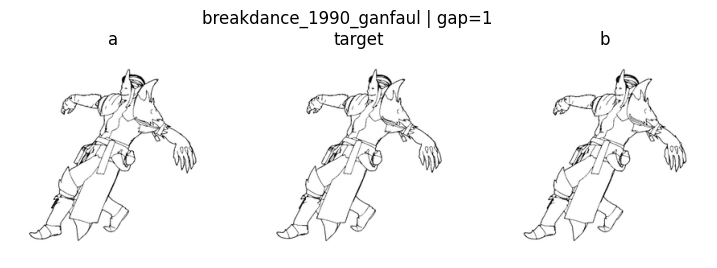

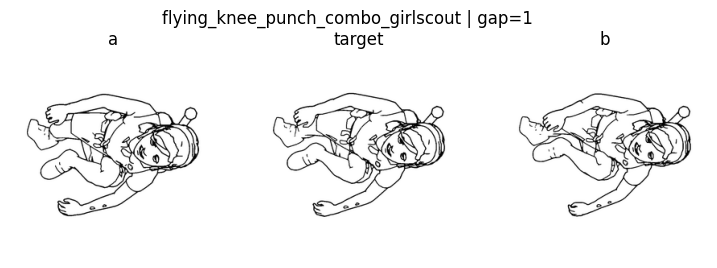

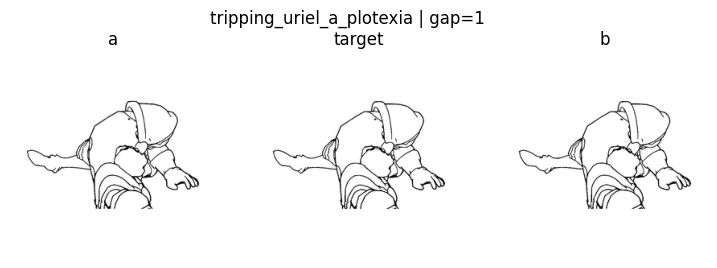

In [ ]:
# Inspect training images, not held-out test results.
train_rows = [r for r in manifest if r["split"] == "train"]

for i in np.linspace(0, len(train_rows) - 1, 3, dtype=int):
    r = train_rows[int(i)]
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))

    for ax, key in zip(axes, ["a", "target", "b"]):
        ax.imshow(raster.read_ink(ROOT / r[key]), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(key)
        ax.axis("off")

    fig.suptitle(r["sequence"] + f" | gap={r['gap']}")
    plt.show()


## Load RAFT-small and check its predictions

Download the pretrained weights and convert them for the TensorFlow implementation. Compare its motion estimates with a saved reference before processing the dataset. RAFT-small stays fixed; [notebook 02](02_baseline_training.ipynb) trains the U-Net that draws the middle frame.

In [ ]:
weights_path = raft_tf.ensure_weights(ROOT, TEMP)
motion = raft_tf.RAFTSmallTF(weights_path, iterations=cfg["raft_iterations"])

import base64, io


REFERENCE_FIXTURE = "UEsDBC0AAAAIAAAAIQDMNyhW//////////8FABQAYS5ucHkBABAAgAABAAAAAAAwAgAAAAAAAO3bMWvbUBiFYXfNr9CmBLykdCihkK1bQ5YMnYqpbTKUuMglSwjkP+QPxx0EpVhGViTf7zvnfUCBeEjuea+HDPHrzd232+8fZo+zp3q52v5s6quq/rL+VM+rer1p/jSLhx+bZrn6+/rXxa/tavf69n7xe7X7/vzy4+d5tftyMa+eq0HOZgAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAACf1ct3/QX7H3DfvBw1j3SHvhVymvifeBzGVuBPeBzGUvoPSv99VtO7RzqMsauuo51ISvXH082WWqWums2aQsWfGM0eUuWPms0eg0E9hQwkqf0up7Dg1pWZKW05BsZfipikod1LeNhblRsrbxuDQx2HjUA5tHDYO4dTFaWtfTk2ctvbl1MRpax+OPRw3d3Fs4bi5i2MLx81dHFs4bt7HuYPz9pZzA+ftLecGzttbzg2ct7ecGyhu//+zcTzjP5GVbuPwKFHc1Jfz9pZzA+ftLecGzttbzg2ct//LsYPj5i6OLRw3d3Fs4bi5i2MLx82HOPVw2tqXUxOnrX05NXHaegyHLg4bh3Jo47DxPZT7KG8bi3Ij5W1jUuykuGlKSr2UtpyKyv+7qOwoQaGbwoaSMvfLfPZIMnbMeObIMvXMdNZMov8tFf18CqI2jnouRdFaRzuPi9LdS/9+lPlslPLnsbKa+nNyU/98jGPfPQ25r7F+Dso5dIfHPsiP+wYAAAAAAAAAAAAAAAAAAAAAAAAAAAAAxPQGUEsDBC0AAAAIAAAAIQDawRjH//////////8FABQAYi5ucHkBABAAgAABAAAAAAAtAgAAAAAAAO3bMUsjURiF4dj6K6abFdIoFiLCdnaKzRZWEkxkC1klERsR/A/+4Y3FgIgTJuNM7ved8z4wgin0nvemsDDvl38urq73Js+Tl3q+WN0u69OqPrs7rqdVffewfFrO/t08LOeLj9fPZ/erxfr11d/Z42L9/a/Do5Nptf5yMK1eq172JwAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAEW9/e7+IL9t7pv3g4ah7pD3Qi5j3xPvg5hK3AnvgxhK30Hp3+8qWvdo51EWtXXUcymJ3jj6+TLL1DXTWTPI2DPjmSPK3DHz2SNQ6KewoQSVv6VUduyaUjOlLbug2Etx0xiUOylvG4pyI+VtQ3Do47CxL4c2Dhv7cOritLUrpyZOW7tyauK0tQvHHo6b2zi2cNzcxrGF4+Y2ji0cN3/HuYPz9oZzA+ftDecGztsbzg2ctzecGyhu//rZOJ7hn8hKt3F4lChu6sp5e8O5gfP2hnMD5+0N5wbO2z9z7OC4uY1jC8fNbRxbOG5u49jCcfMmTj2ctnbl1MRpa1dOTZy2bsOhi8PGvhzaOGz8CeU+ytuGotxIeduQFDspbhqTUi+lLbui8v8uKjtKUOimsKGkzP0ynz2SjB0znjmyTD0znTWT6H9LRT+fgqiNo55LUbTW0c7jonT30r8fZT4bpfx5rKzG/pzc2D8fw/junvrc11A/B+VsusNtH+THfQMAAAAAAAAAAAAAAAAAAAAAAAAAAAAAYvgPUEsDBC0AAAAIAAAAIQBhjSXf//////////8QABQAZXhwZWN0ZWRfbG93Lm5weQEAEACAEAAAAAAAAOMNAAAAAAAAlVaHV1XH1h8QEBDwKhaC7VgiaNDcWFC5M3NOFCMay7XEh35EjwaVKInXXmNGfBrEhr0m3ljRR/Tqx7NwZs45ltjwJdeCBUuOikisV7GgoLzN+v6Cj7VYe+2ZOftX9p5Zd3X/r/o5h/mh6WhOTOqYKd9MjkmQYvDYTjFxUszYiZOnTh71/ciJk1PHVK9/MSp9yhhYn5I2yjUG8tgOcdJn8f/336FNnPSD9P/+C73SJlSefHCiSB8TIv+YtViY6QFynjVKnNzlL7v+Z6iwowBZpNQXbC+Suw4p5M6HlbTDrRVcGltOba8KuNqlgmYoIcKnIrnH6bsc1akhX1x2nTtvBssnOxZyb2iYfORCDlcjAuTLIzpzn4Rk83weVxJf0w1nO4lF+yPltCa54tTSQNn+IVZsmRssqzMbiqlNg2RnWlvh+TpAVn6MFLG6v+wpry889z5Q94bn3BteSd1/FHP15TtqXVrLUa8KyjaO5agn1KfbuJIWIKvqEu6ZEiIrXzHu7RAuo7JDXNoYKKPoXpo6uYKaVft45L9DZPO7X0XSxUBZsfcRTuQvuysHiKkL/GS31VF0ne4vKx8CRfAwP5m9sInyKbBe0Ux4IoBHg3ChvK+k5onn3FxZSZFtNPe+QTLCZ/N9u2vKqEMYz7aHymbrDK50CJVRy/dcXQDrPf/SpNxXVPmrqRj3NFCWmmwTSf41ZGT/RGSvq6LKm49F7p+go1VNYTWroIraSkgTashmkwCRfeINRYv+5ubcdxTtCxFoPOQf1nMz8y1lQRr05T1FHf7k9nH+Mrq/jtu7gd6a+7k3DupH7uHu3v4yG/CEm3vLKBr7gs8N8lE24bCIvQ78n/YUaR3LqZIfLWyAa16sI3Ji/WRlfbhI3gx8RiPhxVBnZCUvj4T6kwT3wD5atZ2jY+8pO7aKm9OgD902cfV7wNHWcNvVABl1z+dm7UqqNAoXatwHivq3FcqCpxR93lCMq/ecmqf/JVRPOUVqkGC5oGNEXxF8CuoUBIps/zeUzaojvHsA50IhtwVUUWT8zs8MAvxOJdz2CtZPeTkrAJxrjPtcsJ5i59480L3kMJfahcjoyR7uDEAyW9laZL8E/odihfW4lLKjU4Qed4+yP93C1v0lZQGtxYZGzymaHSuQ8wVlsfWEzw5+pr8D34D3k4Pc/XE1/nzOzkGfWzTh7CXkXbtwVwbwCM7VWALUx1WabRjg+7ya6wDw8i/kbGclZWdDha8+8Bg6Qij9X1EzeaEYQgH/7U5RfhB0FjQWrknAI72juPbZC4rMKi7NBh8yEoX6eQVF8+sK50Pgs76A5wjAv7uCKysAP3cMV1aC7g0yVxsBfnwX7psKsdNtzfkDRM/aBGXva4o8tbm7I8xLyw3cuvKIsqowkdG5iCo5qwVu85wyK06Yjx5TFNRWdL3/kKI+ZdyylVP2TV3hGgM4n5Xz0n6Au3U39/WBeRlKOQsHX+xIk1To3+Cl3N4a9k8u1JzHgE9eKHdGgy+mW5NaAv/Qedx6Br5MHYHVSdD/xve0uz/dpahZitjS/hlFW7Dw9S6hKCleXNNgv2W4MFdD3csrudII5n2Dl0vhUMc7iDt/AB/iCDcV4IGWHvXdBBxPd4dnMOBnRmBpMOCfWay554B+51XNygHdqx5jtv8tRUOGc/eXFkU5mdrO8bcoyocnrvMDiq45xDXPHYpC2ouofsBrX7BwjYc+LK/i6mm4L40LuXoA+NQbwV1tIBbX4O6agG/2TUCXYD+5PlYjgQcrcqBiwCsejdXOwPfiW+z+FPpeayNRvgMdX2YQqyP4rLYkd2peoWjGQIGbA+5xLw9ecxvmr544MwHy8zncNgt4ji/j6nngV3c5zPETirKOcFcs1F8aytkAiElrHcp20OktdbBhkL+chN29AOfyFozuv6Ro7mHMUDFF0anEzP2boufDCNsB+c0wkhLwH/B/gEj7HHwY8iu3H/iLotOh4kwPyOOPc1fzexRNvcXZN7Cec4x7CqE/L7K5ezXMh7ebxtYDHyQdUc+D/ux1DvW4j6LXmVh5CLjzmhN3PvS1TgsiZd+ibPdWomy9Cu/OQMJuFFFUVIhvzfeCfyHC9vwC6L/Fy6vX653natfroHM7V2w34JzG1RYQl27lrqvAQz2Zr6rAY0gjbDYEH7uOwywc7u2IDxgVAS9XjsPdA+bHHkbUzcDvz1HEXX6DsoXZRJp2E+ouIco40KW/xoeHgv/FgHuokKLg0xw5Ib8eJq59CXnbIm6fCfHMXxx1B55rEPf2uERRYgS3p14GHnn56muYkyEqVuZBf2JfYVYCvuZVYVbjGkVlnYjbukTZ7PmE3SqgzPczURsJ8L+AoKKTFEWMI0vmQP3SLiL1/VGK9rcXZsVFeF+aisw8A/oYKKSI0xRZz7hJzgDeFp6dBf1CS456agF+GndIXQAHJWDrHMyJ6cJKW8h9fgQlwbnknsT6X6i3cSFRBp2mLPkPYnn/oGhPATF776No+0/EnF7XeDe7Lk29EWH0XKiTDv8KN/ovWkWc80ONrAkdCRoaYJyr8wVR2gUa5wY2JddwqLF7XiBRikON9u1246Q+gUbpoUScfcrf2PT7ceyu8V7fFfsrZtpbPdkWgK2cdzqqpXXNXoeM0YsGcXeHMv18dBtNev1Az+nJxLtpDQyJhtK/Vzcw1LmPSPqKCMO9bCVh9cMNpVsiyXwYYlgx8cT9MsgwPa+watY0pPh4Yn0faChNnmJzWaBh3j2Crd0BhjloMc7u52+gfz50qEVVOruapUnDqnTkJAls02sdve/BLY4MJb02l2q+0qWNvQSP+ciwlulkuzfCsL4vJfFWgKG230RSR9YwlOAR5PH2AINd6ECkUGSwgTDPlfD9htqktI+/wdoFkQ3/QAYqCCLSSojmRqyse68jq9zBlpZDLMmXyl7qqO0zh1QT4sjXGjsBfgz9XEOjn+jm7a18ZV49w4o+QcxGAYZ1aS/xDvHpaOxewuf7GSzDRspj/Ayz36fEd6NCN9vEkMwk4HG0EVECAS/xNC4NhHObV2P3btD5Sy+s1oL6EndYCwE/r5NDzQXdsVvyUdFbHQXvSDBvVugoIxqr4/7WUXGMtiyppmFmLSPnFr7W2btMkraoDM4vIr65UCd7MGHrKnXU4h/Et79SZ4kfEV+NDzrrW5f4qt7r7GAwcY4C3GgLq73hvLIWo2ZQ33vNYe76oKMlcdzqDt/PXOQwbz/XkStEs44Br8bzHeqU5zq7F0qCJ73Q2bI2JD6qRGeBDcjMBXCuk0LQxlc6S6pPlOFvdXaiO0EVZTo7Cu9IKtTbUYJRU/DZvwmWer3R0bkfsWmHeDMSq8WAj1IS2C7g9UHi7m8hXi7XFMvPQO4L+RJ+paPEHQ7l2xc6emjHM733dPTbLbzv4xIdeSxHWl/APxpLXAOgfudtOC0JdE3rRmwMfFwfT1zDgH9wEPE2BD+xhs2vIX6xHUuVsM8XYLUf7GfEYTUZ1pWmWNoMfLNzElBziKciuRkC/jp3Jqhu0J8bSUZbpTqaPQJPLXimo127cPKMxzqaYSdRk4Cn/B5nToN4OJS4HzzVUVYRdv4A9X+uRdzTQe8nOrb1gbwqCysTYL5c/TGikE/NwKhG9fw1c6gpoN+KxGYe5KWDHGww9B0jLAXf11F8Ce7YFXh+8CO97TBPsSrZMRx0X4gkzifQv5tfENdEwFfaEV8Q1P8omJgxgEsXYHYbfJm6CNs/gn3nHYdUHdGKBFQOOO5Vmrod/LVb+erCar9XYvbbI9hvmMD+XQjr5Q414YGOSnrwZq1ewhwsJMZpmOP8s2RpJeAULCTmZOCx6ysi3QF+rWKJcwPU+7kByb4C+39wrDjBr+KlWLoCcdtybEVD9DTBam3wzxuPlcXQR9bJoayuXp+J3d9Af5OjuHKrCHh01tBvZyG+OJq/o4aBPr1BXL8EGcz0keL0JzqaU0J8s0Df8RGkvDPotcYQ232op7cmygzo845z2Ft9r9PfYSm+el41jKIgntyB3Z0hRoVhaWKxjoZv5MpI6LfN6VDioH8RWZyl3NVRqotLPf+jo7DF/Od9oPv2XRK1Gd4rvzJSvBd8mech9hmgf9+3xLwK9WZJxOQQo1sRVxLEFr9jtwLvRMlyjIaBvqQ8hzUI1sMkzBrDPJ1cxtUpwDOpHkb7HwL/LvD7C3zpn8nZAcA/s0JTg65AnM4TzsJc5ueRsJPQn3FvSKe693U2UCOWDH1LWEC8s6vx2hCrEHw5ZiOepxBzxmBfIeD6dmMzBHhE3XCgpnBO2e8wZwEeIwnuZJiz5FlYfQO4S6O4ehzyqXkcNYac2zlqDv0IfqS1bw5zdz2deCLBr+XDyZpjN3Q0eBYxm8H5r5eQ5BQ4t6QZ8T2CexrUlNiuQv50G/ZFAY8redjqCDxz/bD7APQjpT74Afq9uQ7zAZxLUzAaDnpRMEZfw7zbSzQlHPpQvk9TxsL5xE74XTb4nHlIM+fAnKX+kziLoV+hO3BSBdTZ6E/YW/iuSzhx+0GMbE48EcCrbha2fQbfO886zGkwH9nfQYT3Zct3GE2C9ajlmtoQzuXkaupLwDczNHQYvseEs0TQgZoedZ8GH1jF0TV94b6cj8ZHasO8pRRj+w14X+8sIu4c6F/uAYxKq/uXgu2bburoxS/YfeIO4N3AaDzwC07DLjvoscdhdh98yCQY7QE+jxOwUlQ9d70w23kb8A52RT9BtOY6kOeWjtRPNHUt9D90E/8vUEsBAi0DLQAAAAgAAAAhAMw3KFYwAgAAgAABAAUAAAAAAAAAAAAAAIABAAAAAGEubnB5UEsBAi0DLQAAAAgAAAAhANrBGMctAgAAgAABAAUAAAAAAAAAAAAAAIABZwIAAGIubnB5UEsBAi0DLQAAAAgAAAAhAGGNJd/jDQAAgBAAABAAAAAAAAAAAAAAAIABywQAAGV4cGVjdGVkX2xvdy5ucHlQSwUGAAAAAAMAAwCkAAAA8BIAAAAA"

with np.load(io.BytesIO(base64.b64decode(REFERENCE_FIXTURE))) as fixture:
    actual = motion.bidirectional_low(fixture["a"], fixture["b"])
    error = float(np.max(np.abs(actual - fixture["expected_low"])))

    assert error < 0.02, f"RAFT reference check failed: low-grid max error {error}"


print("RAFT reference low-grid max error:", error)


a = np.zeros((16, 16), np.float32)
a[6, 4] = 1

flow = np.zeros((2, 16, 16), np.float32)
flow[0] = 4

warp, _ = raster.forward_splat(a, flow)


assert warp[6, 6] == 1, "Forward-splat direction check failed."


RAFT reference low-grid max error: 2.0489096641540527e-06


## Save motion estimates and export Stage 1

Compute motion in both directions for every example. Save compact float16 motion grids in chunks; later notebooks expand them to build the U-Net inputs. The preview shows the endpoint drawings, rough middle drawings, and true middle. The final cell packages Stage 1 as a ZIP.

**Resume:** save the partial Kaggle output, attach it in a new session, and set `RESUME_DATA_ROOT` to that folder. Completed rows are reused. Save outputs before the session ends.

In [ ]:
assert shutil.disk_usage(ROOT).free > max(2 * 1024**3, cache_bytes), (
    "Insufficient free disk for the full motion cache."
)

t0 = time.perf_counter()
raster.cache_flows(ROOT, motion, progress_every=25)

print("This cache invocation minutes:", round((time.perf_counter() - t0) / 60, 1))


train already cached 0 of 58390
train 25 / 58390 elapsed minutes 0.2
train 50 / 58390 elapsed minutes 0.3
train 75 / 58390 elapsed minutes 0.4
train 100 / 58390 elapsed minutes 0.5
train 125 / 58390 elapsed minutes 0.6
train 150 / 58390 elapsed minutes 0.7
train 175 / 58390 elapsed minutes 0.8
train 200 / 58390 elapsed minutes 0.9
train 225 / 58390 elapsed minutes 1.0
train 250 / 58390 elapsed minutes 1.1
train 275 / 58390 elapsed minutes 1.2
train 300 / 58390 elapsed minutes 1.2
train 325 / 58390 elapsed minutes 1.3
train 350 / 58390 elapsed minutes 1.4
train 375 / 58390 elapsed minutes 1.5
train 400 / 58390 elapsed minutes 1.6
train 425 / 58390 elapsed minutes 1.7
train 450 / 58390 elapsed minutes 1.8
train 475 / 58390 elapsed minutes 1.9
train 500 / 58390 elapsed minutes 2.0
train 525 / 58390 elapsed minutes 2.1
train 550 / 58390 elapsed minutes 2.2
train 575 / 58390 elapsed minutes 2.3
train 600 / 58390 elapsed minutes 2.4
train 625 / 58390 elapsed minutes 2.4
train 650 / 58390 ela

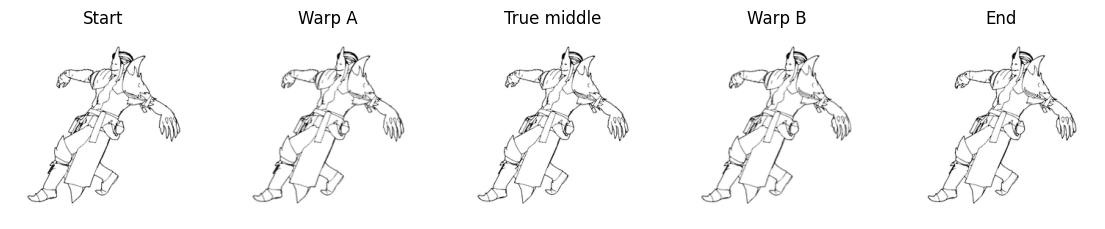

STAGE 1 COMPLETE: /kaggle/working/interframes_tf_stage1
Same session: notebook 02 finds this folder automatically. Fresh session: save and attach this output.


In [ ]:
r = next(r for r in manifest if r["split"] == "train")

flows = raster.open_flows(ROOT, "train")
x = raster.row_features(ROOT, r, flows)
fig, axes = plt.subplots(1, 5, figsize=(14, 3))


for ax, arr, title in zip(
    axes,
    [x[..., 0], x[..., 2], raster.read_ink(ROOT / r["target"]), x[..., 3], x[..., 1]],
    ["Start", "Warp A", "True middle", "Warp B", "End"],
):
    ax.imshow(arr, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


plt.show()

fingerprint, fields = raster.bundle_fingerprint(ROOT)

for split in ["train", "val", "test"]:
    done = np.load(ROOT / "flows" / f"{split}_done.npy", mmap_mode="r")
    assert bool(done.all())

raster.json_save(
    ROOT / "stage1_complete.json",
    dict(
        fingerprint=fingerprint,
        fields=fields,
        triplets=dict(Counter(r["split"] for r in manifest)),
        scope="full",
        tensorflow=tf.__version__,
        keras=keras.__version__,
    ),
)


print("STAGE 1 COMPLETE:", ROOT)
print(
    "Same session: notebook 02 finds this folder automatically. Fresh session: save and attach this output."
)


In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_STORED
from IPython.display import FileLink, display
import os
import shutil

source = Path("/kaggle/working/interframes_tf_stage1")
archive = source.with_suffix(".zip")
partial = archive.with_suffix(".zip.part")

if not (source / "stage1_complete.json").is_file():
    raise RuntimeError("Wait until notebook 01 prints STAGE 1 COMPLETE.")

files = sorted(path for path in source.rglob("*") if path.is_file())
required = sum(path.stat().st_size for path in files)
if shutil.disk_usage(source.parent).free < required + 64 * 1024**2:
    raise RuntimeError(
        "There isn't enough free Kaggle disk space to create the backup ZIP."
    )

# Store without recompressing to keep backup creation fast.
with ZipFile(partial, "w", compression=ZIP_STORED, allowZip64=True) as zip_file:
    for path in files:
        zip_file.write(path, arcname=path.relative_to(source.parent))

with ZipFile(partial) as zip_file:
    bad_file = zip_file.testzip()
    if bad_file:
        raise RuntimeError(f"ZIP verification failed for {bad_file}")

partial.replace(archive)
print(
    f"Verified {len(files):,} files. ZIP size: {archive.stat().st_size / 1024**3:.2f} GiB"
)
display(FileLink(os.path.relpath(archive), result_html_prefix="Download: "))